# Lohmann_Exploration.ipynb
**ICS 3202 — Artificial Intelligence | Project Deliverable 1 (revised)**

**Project:** An Integrated Enterprise Resource Planning System for Poultry Farm Management

**Dataset:** [Historical performance of Lohmann Brown-Classic laying hens in Colombia](https://data.mendeley.com/datasets/t2gzbht99m)
(Cabezas-García, Rodríguez-Aguilar & Betancourt López, 2024, Mendeley Data, CC BY 4.0).
Weekly production records of 9 commercial flocks of about 1,500 hens each, kept on a farm in Mosquera, Colombia, from 2003 to 2015.
Each flock is recorded from 19 to 71 weeks of age.

**Expected output variable of the final application:** the flock's **laying rate** (the share of hens laying per day, %)
1, 4 and 8 weeks ahead. This feeds the ERP's **Production Tracking** module (expected eggs, early warning when a flock
is heading below the breed standard) and **Feed Management** module (feed per dozen eggs).

**Why the dataset changed.** The first version of this project used the Kaggle *Egg Producing Chickens* dataset. Its target turned
out to be decided by one rule (every hen older than about 950 days lays 0 eggs, every younger hen lays 1), so a model could only
rediscover that rule. That work is kept in `archive/v1-egg-producing-chickens/`.

## Dataset discovery (Instructions 1 & 2)

Every candidate was downloaded and checked before choosing: duplicate rows, whether one column alone gives the answer,
and how far a simple model beats a naive guess.

| Dataset | Source | Candidate output variable | Verdict |
|---|---|---|---|
| **Lohmann Brown-Classic flock records** (selected) | Mendeley Data `t2gzbht99m` | weekly laying rate per flock | real farm data, 9 flocks × 52 weeks; models beat simple rules but not trivially |
| Egg Producing Chickens | Kaggle `phuzoman/egg-producing-chickens` | `EggsPerDay` | rejected: the 1,000 rows are 190 birds copied; age alone decides the 0/1 target |
| Prediction of Egg Production Rate in Poultry | Kaggle `deepikabidri/prediction-of-egg-production-rate-in-poultry` | High / Medium / Low production | rejected: each class was generated in its own range of every column, so any one column scores 100% |
| Environmental Effect on Egg Production | Kaggle `faysal1998/environmental-effect-on-egg-production` | total eggs | rejected: 481 rows are 74 unique ones (a 2-month log pasted ~8 times) |
| Hy-Line Brown individual egg production | Mendeley Data `kwys7yscfb` | weekly eggs per hen | weaker: 40 hens; only age predicts (R² ≈ 0.33), diet and body weight add nothing |

## Setup — load the dataset

In [1]:
# The file is tab-separated. A copy ships in the repo's data/ folder; in Colab it
# is downloaded from Mendeley Data, which refuses requests without a browser-like
# User-Agent header.
import io, os, urllib.request
import pandas as pd

LOCAL_COPY = 'data/lohmann_brown_flocks.txt'
URL = ('https://data.mendeley.com/public-files/datasets/t2gzbht99m/files/'
       '5dfb5617-19d0-4307-b969-3ac722b1c12b/file_downloaded')

if os.path.exists(LOCAL_COPY):
    df = pd.read_csv(LOCAL_COPY, sep='\t')
else:
    request = urllib.request.Request(URL, headers={'User-Agent': 'Mozilla/5.0'})
    df = pd.read_csv(io.BytesIO(urllib.request.urlopen(request).read()), sep='\t')

df.head()

,Year,Generation,Flock,WeekOld,ProdWeek,HousedHens,BirdsBalance,NumberEggsPerWeek,FeedPerWeek,MortalityCullingRateWeek,...,LayingRateDay,IdealLayingRateDay,LayingRateHenHoused,IdealLayingRateHenHoused,FeedConvertionPerDozenEggs,NEggsHenWeek,CummNEggsHen,NEggsHenHousedWeek,CummNEggsHenHousedWeek,IdealCummNEggsHenHousedWeek
0,2003.0,1.0,1.0,20.0,1.0,1548.0,1548.0,4.0,930.81,0.0,...,0.04,40.0,0.04,40.0,2792.44,0.00,0.00,0.00,0.00,3.9
1,2003.0,1.0,1.0,21.0,2.0,1548.0,1548.0,17.0,934.50,0.0,...,0.16,60.1,0.16,60.0,659.64,0.01,0.01,0.01,0.01,8.1
2,2003.0,1.0,1.0,22.0,3.0,1548.0,1548.0,148.0,937.86,0.0,...,1.37,75.2,1.37,75.0,76.04,0.10,0.11,0.10,0.11,13.3
3,2003.0,1.0,1.0,23.0,4.0,1548.0,1548.0,606.0,937.86,0.0,...,5.59,85.3,5.59,85.0,18.57,0.39,0.50,0.39,0.50,19.3
4,2003.0,1.0,1.0,24.0,5.0,1548.0,1548.0,1864.0,977.95,0.0,...,17.20,90.5,17.20,90.0,6.30,1.20,1.70,1.20,1.70,25.6


In [2]:
# Column names, so the exact spelling used below can be checked against the file
print(df.columns.tolist())

['Year', 'Generation', 'Flock', 'WeekOld', 'ProdWeek', 'HousedHens', 'BirdsBalance', 'NumberEggsPerWeek', 'FeedPerWeek', 'MortalityCullingRateWeek', 'CummMortalityCullingRate', 'FeedIntake', 'LayingRateDay', 'IdealLayingRateDay', 'LayingRateHenHoused', 'IdealLayingRateHenHoused', 'FeedConvertionPerDozenEggs', 'NEggsHenWeek', 'CummNEggsHen', 'NEggsHenHousedWeek', 'CummNEggsHenHousedWeek', 'IdealCummNEggsHenHousedWeek']


## a. How many rows and columns are contained in the dataset? (3 marks)

In [3]:
# shape returns the dimensions as a (rows, columns) tuple
num_rows, num_cols = df.shape

print("Rows:", num_rows)
print("Columns:", num_cols)

Rows: 469
Columns: 22


469 rows: 9 flocks × 52 weeks = 468 flock-weeks, plus one empty row at the end of the file (see part c).

## b. What datatypes are contained in the dataset? (3 marks)

In [4]:
# dtypes shows the type pandas inferred for each column when reading the file.
# float64/int64 are numbers; object/str is text.
df.dtypes

Year                           float64
Generation                     float64
Flock                          float64
WeekOld                        float64
ProdWeek                       float64
HousedHens                     float64
BirdsBalance                   float64
NumberEggsPerWeek              float64
FeedPerWeek                    float64
MortalityCullingRateWeek       float64
CummMortalityCullingRate       float64
FeedIntake                     float64
LayingRateDay                  float64
IdealLayingRateDay                 str
LayingRateHenHoused            float64
IdealLayingRateHenHoused           str
FeedConvertionPerDozenEggs     float64
NEggsHenWeek                   float64
CummNEggsHen                   float64
NEggsHenHousedWeek             float64
CummNEggsHenHousedWeek         float64
IdealCummNEggsHenHousedWeek        str
dtype: object

Every column is numeric except `IdealLayingRateDay`, which pandas read as text. That means at least one of its values
is not a number, which part c tracks down.

## c. Is the dataset complete? i.e. no missing values? (2 marks)

In [5]:
# isnull() marks every empty cell True; summing down each column counts them
print(df.isnull().sum())
print()
print("Total missing values:", df.isnull().sum().sum())

Year                           1
Generation                     1
Flock                          1
WeekOld                        1
ProdWeek                       1
HousedHens                     1
BirdsBalance                   1
NumberEggsPerWeek              1
FeedPerWeek                    1
MortalityCullingRateWeek       1
CummMortalityCullingRate       1
FeedIntake                     1
LayingRateDay                  1
IdealLayingRateDay             1
LayingRateHenHoused            1
IdealLayingRateHenHoused       1
FeedConvertionPerDozenEggs     1
NEggsHenWeek                   1
CummNEggsHen                   1
NEggsHenHousedWeek             1
CummNEggsHenHousedWeek         1
IdealCummNEggsHenHousedWeek    1
dtype: int64

Total missing values: 22


In [6]:
# Where are they? Every column is empty in the same row - the blank last line of the file.
print(df[df.isnull().any(axis=1)])

# IdealLayingRateDay was read as text: find the values that aren't numbers
ideal_numeric = pd.to_numeric(df['IdealLayingRateDay'], errors='coerce')
print()
print(df.loc[ideal_numeric.isna() & df['IdealLayingRateDay'].notna(),
             ['Generation', 'Flock', 'WeekOld', 'IdealLayingRateDay']])

     Year  Generation  Flock  WeekOld  ProdWeek  HousedHens  BirdsBalance  \
468   NaN         NaN    NaN      NaN       NaN         NaN           NaN   

     NumberEggsPerWeek  FeedPerWeek  MortalityCullingRateWeek  ...  \
468                NaN          NaN                       NaN  ...   

     LayingRateDay  IdealLayingRateDay  LayingRateHenHoused  \
468            NaN                 NaN                  NaN   

    IdealLayingRateHenHoused  FeedConvertionPerDozenEggs NEggsHenWeek  \
468                      NaN                         NaN          NaN   

     CummNEggsHen  NEggsHenHousedWeek  CummNEggsHenHousedWeek  \
468           NaN                 NaN                     NaN   

     IdealCummNEggsHenHousedWeek  
468                          NaN  

[1 rows x 22 columns]

     Generation  Flock  WeekOld IdealLayingRateDay
51          1.0    1.0     71.0                  .
155         1.0    3.0     71.0                  .


**Not quite complete.** There is one fully empty row (the blank line at the end of the file), which is simply dropped.
Two values of `IdealLayingRateDay`, the breed standard at 71 weeks for two generation-1 flocks, are recorded as `"."`.
The breed standard is only used up to 70 weeks, so those two values are never needed. Every real record is otherwise complete.

## d. Slice out the first 15 rows and last 20 rows, merge into `df_sample`, display it (4 marks)

In [7]:
# head() takes rows from the top, tail() from the bottom
first_15 = df.head(15)
last_20 = df.tail(20)

# concat stacks the two slices. ignore_index renumbers the rows 0-34 instead of
# carrying over the original row numbers.
df_sample = pd.concat([first_15, last_20], ignore_index=True)

df_sample

,Year,Generation,Flock,WeekOld,ProdWeek,HousedHens,BirdsBalance,NumberEggsPerWeek,FeedPerWeek,MortalityCullingRateWeek,...,LayingRateDay,IdealLayingRateDay,LayingRateHenHoused,IdealLayingRateHenHoused,FeedConvertionPerDozenEggs,NEggsHenWeek,CummNEggsHen,NEggsHenHousedWeek,CummNEggsHenHousedWeek,IdealCummNEggsHenHousedWeek
0,2003.0,1.0,1.0,20.0,1.0,1548.0,1548.0,4.0,930.81,0.00,...,0.04,40.0,0.04,40.0,2792.44,0.00,0.00,0.00,0.00,3.9
1,2003.0,1.0,1.0,21.0,2.0,1548.0,1548.0,17.0,934.50,0.00,...,0.16,60.1,0.16,60.0,659.64,0.01,0.01,0.01,0.01,8.1
2,2003.0,1.0,1.0,22.0,3.0,1548.0,1548.0,148.0,937.86,0.00,...,1.37,75.2,1.37,75.0,76.04,0.10,0.11,0.10,0.11,13.3
3,2003.0,1.0,1.0,23.0,4.0,1548.0,1548.0,606.0,937.86,0.00,...,5.59,85.3,5.59,85.0,18.57,0.39,0.50,0.39,0.50,19.3
4,2003.0,1.0,1.0,24.0,5.0,1548.0,1548.0,1864.0,977.95,0.00,...,17.20,90.5,17.20,90.0,6.30,1.20,1.70,1.20,1.70,25.6
5,2003.0,1.0,1.0,25.0,6.0,1548.0,1547.0,3852.0,1048.38,0.06,...,35.57,92.6,35.55,92.0,3.27,2.49,4.19,2.49,4.19,32.0
6,2003.0,1.0,1.0,26.0,7.0,1548.0,1546.0,6253.0,1137.05,0.06,...,57.78,93.2,57.71,92.6,2.18,4.04,8.24,4.04,8.23,38.5
7,2003.0,1.0,1.0,27.0,8.0,1548.0,1546.0,7575.0,1190.42,0.00,...,70.00,93.8,69.91,92.8,1.89,4.90,13.14,4.89,13.13,45.0
8,2003.0,1.0,1.0,28.0,9.0,1548.0,1545.0,9002.0,1190.42,0.06,...,83.24,93.8,83.07,93.0,1.59,5.83,18.97,5.82,18.94,51.5
9,2003.0,1.0,1.0,29.0,10.0,1548.0,1545.0,9535.0,1226.75,0.00,...,88.16,93.9,87.99,92.8,1.54,6.17,25.14,6.16,25.10,58.0


---
## Additional exploration (beyond the required questions)

In [8]:
df = df.dropna(how='all').reset_index(drop=True)
df['Ideal'] = pd.to_numeric(df['IdealLayingRateDay'], errors='coerce')
df['flock_id'] = 'G' + df['Generation'].astype(int).astype(str) + '-F' + df['Flock'].astype(int).astype(str)

print("Duplicate rows:", df.duplicated().sum())
df.groupby('flock_id').agg(
    year=('Year', 'min'), weeks=('WeekOld', 'size'),
    first_week=('WeekOld', 'min'), last_week=('WeekOld', 'max'),
    hens_housed=('HousedHens', 'first'),
    mean_laying_rate=('LayingRateDay', 'mean'),
    peak_laying_rate=('LayingRateDay', 'max'),
).round(1)

Duplicate rows: 0


,year,weeks,first_week,last_week,hens_housed,mean_laying_rate,peak_laying_rate
flock_id,,,,,,,
G1-F1,2003.0,52,20.0,71.0,1548.0,74.9,95.0
G1-F2,2003.0,52,19.0,70.0,1548.0,79.2,96.2
G1-F3,2005.0,52,20.0,71.0,1548.0,80.7,95.8
G2-F1,2009.0,52,19.0,70.0,1415.0,81.1,98.1
G2-F2,2010.0,52,19.0,70.0,1548.0,75.9,94.9
G2-F3,2012.0,52,19.0,70.0,1548.0,86.9,97.4
G3-F1,2013.0,52,19.0,70.0,1548.0,83.9,96.1
G3-F2,2014.0,52,19.0,70.0,1548.0,84.7,104.6
G3-F3,2015.0,52,19.0,70.0,1548.0,86.7,97.4


No duplicates, unlike the Kaggle datasets that were rejected. There are 9 flocks with 52 consecutive weeks each.

### Which columns are raw records, and which are calculated from them?

In [9]:
# If a column can be rebuilt exactly from other columns, it carries no new
# information - and if it is built from the eggs, using it as an input would
# leak the answer into the model.
import numpy as np
rebuilt = {
    'LayingRateDay  = eggs / hens / 7 x 100': df['NumberEggsPerWeek'] / df['BirdsBalance'] / 7 * 100 - df['LayingRateDay'],
    'FeedIntake     = feed kg x 1000 / hens / 7': df['FeedPerWeek'] * 1000 / df['BirdsBalance'] / 7 - df['FeedIntake'],
    'NEggsHenWeek   = eggs / hens': df['NumberEggsPerWeek'] / df['BirdsBalance'] - df['NEggsHenWeek'],
}
for name, diff in rebuilt.items():
    print(f"{name}   largest difference: {diff.abs().max():.3f}")

LayingRateDay  = eggs / hens / 7 x 100   largest difference: 0.005
FeedIntake     = feed kg x 1000 / hens / 7   largest difference: 0.050
NEggsHenWeek   = eggs / hens   largest difference: 0.005


The farm actually records five things each week: **hens alive** (`BirdsBalance`), **eggs collected** (`NumberEggsPerWeek`),
**feed used** (`FeedPerWeek`, kg), **deaths** (the drop in hens), and the flock's **age**. Everything else, including the laying rate
itself, is arithmetic on those. So the model takes only those five records as input. Rates are recalculated from them
the same way for training and for live use.

### Laying curves: every flock against the breed standard

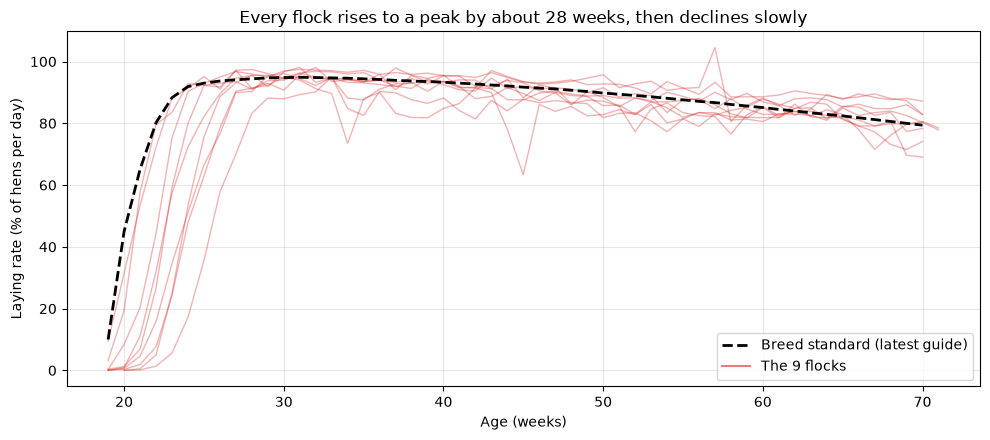

In [10]:
import matplotlib.pyplot as plt

latest = df[df['Generation'] == 3].groupby('WeekOld')['Ideal'].median()

fig, ax = plt.subplots(figsize=(10, 4.5))
for flock_id, rows in df.groupby('flock_id'):
    ax.plot(rows['WeekOld'], rows['LayingRateDay'], color='tab:red', alpha=0.35, linewidth=1)
ax.plot(latest.index, latest.values, color='black', linestyle='--', linewidth=2, label='Breed standard (latest guide)')
ax.plot([], [], color='tab:red', alpha=0.6, label='The 9 flocks')
ax.set_xlabel('Age (weeks)'); ax.set_ylabel('Laying rate (% of hens per day)')
ax.set_title('Every flock rises to a peak by about 28 weeks, then declines slowly')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

- **Start of lay varies the most.** Some flocks reach 80% by week 25 and others only by week 28. That is where the breed standard is furthest off.
- **After the peak, flocks decline slowly, with sudden dips.** A dip of 10 points in one week happens a few times, for example from disease,
  stress or a feed problem. A forecaster has to tell these dips from a real decline.
- **The breed guide changed.** Generation 1 (2003–2005) used an older, lower standard curve. The model uses the latest guide throughout.

In [11]:
pivot = df.pivot_table(index='WeekOld', columns='Generation', values='Ideal')
pivot.iloc[::6].round(1)

Generation,1.0,2.0,3.0
WeekOld,,,
19.0,15.0,10.0,10.0
25.0,92.6,93.1,93.0
31.0,93.5,95.0,94.9
37.0,91.8,94.0,93.9
43.0,89.2,92.5,92.4
49.0,86.1,90.4,90.3
55.0,82.5,87.6,87.6
61.0,78.5,84.0,84.5
67.0,73.9,79.9,81.2


### How strongly does this week predict later weeks?

In [12]:
# Correlation between the laying rate now and the rate h weeks later, after the
# peak (week 30 on), where the flock is in steady production
df = df.sort_values(['flock_id', 'WeekOld'])
steady = df[df['WeekOld'] >= 30]
for h in (1, 4, 8):
    later = df.groupby('flock_id')['LayingRateDay'].shift(-h)
    pair = pd.DataFrame({'now': df['LayingRateDay'], 'later': later})[df['WeekOld'] >= 30].dropna()
    print(f"{h} week(s) ahead: correlation {pair['now'].corr(pair['later']):.2f}  (n={len(pair)})")

1 week(s) ahead: correlation 0.81  (n=362)
4 week(s) ahead: correlation 0.73  (n=335)
8 week(s) ahead: correlation 0.65  (n=299)


In steady production, this week's rate is a strong guide to next week's (correlation 0.81) and a weaker one to two months
ahead (0.65). That is why the forecaster also
uses the flock's age, its recent trend and the breed curve, and why its scores fall as the horizon grows (see `LayingRate_Model.ipynb`).

## Notes / next steps
- **Target:** the laying rate 1, 4 and 8 weeks ahead, a regression problem with one model per horizon.
- **Inputs:** age, this week's and the two previous weeks' laying rate, the trend, feed per hen, mortality, and the breed standard now and at the target week.
- **Evaluation must be by flock** (train on 8, test on the 9th). Weeks of one flock are alike, so a random split would let the model peek.
- **Limitation:** one farm, one breed, one country, so the results are a strong proof of concept for the ERP, not a guarantee for Kenyan flocks.